# Milán – ORC termodinamikai modell (névleges állapot)

Négy állapotpont CoolProppal, izentropikus komponenshatásfokok, hőcserélő-pinch, munkaközeg-előszűrés, T–s és p–h diagramok.

A számítás az orc_thermo.py fájl függvényében van. A bemenetek között van a munkaközeg, a forráshőmérséklet, a külső hőmérséklet, a kúthozam és az elpárolgási nyomás. A modul nem készít éves termelési görbét, és nem optimalizál elpárolgási nyomást vagy munkaközeget.



## 1. A számítás fizikai alapja

Az egyszerű, szubkritikus ORC négy állapotpontja:

1. Kondenzátor kilépő oldala: telített folyadék az alacsony nyomáson.
2. ORC-tápszivattyú után: nagynyomású folyadék.
3. Elpárologtató után: túlhevített gőz, a turbina belépése.
4. Turbina után: kisnyomású munkaközeg, a kondenzátor belépése.

Az izentropikus referenciaállapotokat 2s és 4s jelöli. A valós gépekre:

$$h_2=h_1+\frac{h_{2s}-h_1}{\eta_p},\qquad h_4=h_3-\eta_t(h_3-h_{4s}).$$

$$\dot Q_{\mathrm{be}}=\dot m_{\mathrm{ORC}}(h_3-h_2),\quad
P_{\mathrm{turb}}=\dot m_{\mathrm{ORC}}(h_3-h_4),\quad
P_{\mathrm{ORC,pump}}=\dot m_{\mathrm{ORC}}(h_2-h_1).$$

$$P_{\mathrm{ciklus}}=P_{\mathrm{turb}}-P_{\mathrm{ORC,pump}},\qquad
\eta_{\mathrm{ciklus}}=\frac{P_{\mathrm{ciklus}}}{\dot Q_{\mathrm{be}}}.$$

Az ORC tömegáramát úgy határozzuk meg, hogy a termálvíz és a munkaközeg hőmérséklet-különbsége a hőcserélő mentén ne essen a megadott minimum alá, továbbá a termálvíz kilépő hőmérséklete ne legyen a beállított minimum alatt.

**Rendszerhatár:** a fenti P_ciklus még nem a teljes geotermikus erőmű nettó villamos teljesítménye! Le kell vonni a kútvízszivattyúk és a léghűtés ventilátorainak fogyasztását; a generátor veszteségét is a teljes rendszer számításában lehet figyelembe venni. Hanna!


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from CoolProp.CoolProp import PropsSI
from orc_thermo import DEFAULT_FLUIDS, evaporation_pressure_bar, calculate_orc

# Nevleges, elozetes tervezesi feltevesek; nem helyszini meresi adatok.
T_SOURCE_C = 115.0          # 125 Celsius kutfenekhomerseklet, feltetelezett 10 K veszteseg
T_AIR_C = 13.53             # korabbi projektben hasznalt nevleges kulso homerseklet
M_BRINE_KG_S = 40.0         # termalviz egy termelokutra
T_EVAP_REF_C = 85.0        # csak kozos eloszuresi osszehasonlito allapot
ETA_TURBINE = 0.80
ETA_PUMP = 0.70
PINCH_K = 8.0
SUPERHEAT_K = 3.0
CONDENSER_APPROACH_K = 15.0
T_BRINE_OUT_MIN_C = 65.0

def run_nominal(fluid):
    p_evap = evaporation_pressure_bar(fluid, T_EVAP_REF_C)
    return calculate_orc(
        fluid=fluid,
        T_source_C=T_SOURCE_C,
        T_air_C=T_AIR_C,
        m_brine_kg_s=M_BRINE_KG_S,
        p_evap_bar=p_evap,
        eta_turbine=ETA_TURBINE,
        eta_pump=ETA_PUMP,
        pinch_K=PINCH_K,
        superheat_K=SUPERHEAT_K,
        condenser_approach_K=CONDENSER_APPROACH_K,
        T_brine_out_min_C=T_BRINE_OUT_MIN_C,
    )

print("Nevleges parameterek: forras =", T_SOURCE_C, "°C; levego =", T_AIR_C,
      "°C; vízhozam =", M_BRINE_KG_S, "kg/s; elparolgas =", T_EVAP_REF_C, "°C")


Névleges paraméterek: forrás = 115.0 °C; levegő = 13.53 °C; vízhozam = 40.0 kg/s; elpárolgás = 85.0 °C


## 2. Előzetes munkaközeg-összehasonlítás

A három közeget azonos elpárolgási hőmérsékleten hasonlítjuk össze. A különböző szaturációs nyomásokat a CoolProp számítja. Ez tisztességes névleges összevetés, de nem éves optimum, és nem helyettesíti a biztonsági és környezeti vizsgálatot.

A táblázat P_ciklus értéke csak a turbinát és a belső ORC-szivattyút tartalmazza.


In [ ]:
candidate_results = {}
rows = []
for fluid in DEFAULT_FLUIDS:
    try:
        result = run_nominal(fluid)
        candidate_results[fluid] = result
        perf = result["performance"]
        rows.append({
            "Kozeg": fluid,
            "p_elp [bar]": evaporation_pressure_bar(fluid, T_EVAP_REF_C),
            "p_kond [bar]": result["states"]["1"]["p_bar"],
            "m_ORC [kg/s]": perf["m_orc_kg_s"],
            "P_ciklus [kW]": perf["P_cycle_net_kW"],
            "eta_ciklus [%]": 100 * perf["eta_cycle"],
            "T_víz,ki [°C]": perf["T_brine_out_C"],
            "min. pinch [K]": perf["min_actual_pinch_K"],
        })
    except ValueError as err:
        print(f"{fluid}: ez a nevleges allapot nem megvalosithato: {err}")

comparison = pd.DataFrame(rows).set_index("Kozeg")
print(comparison.round(3).to_string())
assert len(candidate_results) == 3, "Nem mindharom munkakozeg adott ervenyes allapotot."


            p_elp [bar]  p_kond [bar]  m_ORC [kg/s]  P_ciklus [kW]  eta_ciklus [%]  T_víz,ki [°C]  min. pinch [K]
Közeg                                                                                                            
R245fa            8.925         1.690        24.025        580.638          10.422         81.678             8.0
R1233zd(E)        7.427         1.476        23.322        567.242          10.646         83.131             8.0
R600a            14.874         3.882        14.670        592.765          10.109         79.929             8.0


### Előzetes közegválasztás

- **R245fa:** jól ismert ORC-közeg, de a globális felmelegedési potenciálja miatt környezetvédelmi hátránya van.
- **R1233zd(E):** alacsonyabb GWP-jű jelölt, ebben a notebookban ezzel ábrázoljuk a részletes állapotpontokat.
- **R600a (izobután):** termodinamikailag versenyképes lehet, de a gyúlékonyság tervezési és biztonsági hátrány.

Ez nem végleges döntés. Az éves energiatermelés és az optimalizált elpárolgási nyomás alapján Hanna végzi a végső összehasonlítást. Nem szabad pusztán a mostani három névleges ciklusteljesítmény alapján kimondani az éves győztest.

Anyagtulajdonságok: [CoolProp High-Level API](https://coolprop.org/coolprop/HighLevelAPI.html). Környezeti háttér: [US EPA GWP reference table](https://www.epa.gov/hfcs/technology-transitions-gwp-reference-table). A biztonsági besorolást és a tényleges alkalmazási követelményeket részletes tervezéskor külön ellenőrizni kell.


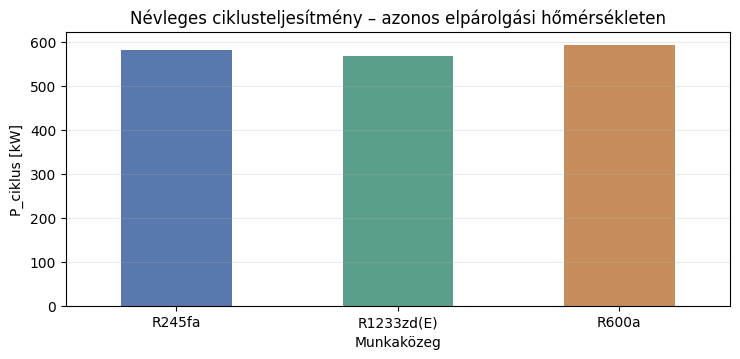

In [ ]:
fig, ax = plt.subplots(figsize=(7.5, 3.7))
comparison["P_ciklus [kW]"].plot.bar(ax=ax, color=["#5978ae", "#5a9f8b", "#c78c5b"])
ax.set(ylabel="P_ciklus [kW]", xlabel="Munkaközeg",
       title="Nevleges ciklusteljesitmeny - azonos elparolgasi homersekleten")
ax.grid(axis="y", alpha=0.25)
ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
plt.show()


## 3. A négy állapotpont és az energiamérleg

Az ábrázoláshoz **R1233zd(E)** munkaközeget választunk előzetesen. A táblázat a CoolProp által meghatározott T, p, h, s értékeket tartalmazza.

Az entalpia és entrópia abszolút nullapontja a CoolProp referenciájától függ; a fizikailag lényeges mennyiségek az entalpiakülönbségek!!!!


In [ ]:
REFERENCE_FLUID = "R1233zd(E)"
reference = candidate_results[REFERENCE_FLUID]
states_df = pd.DataFrame.from_dict(reference["states"], orient="index")
states_df.index.name = "allapotpont"
print("A negy allapotpont:")
print(states_df.round(3).to_string())

print("\nIzentropikus referenciaallapotok (ellenorzeshez):")
print(pd.DataFrame.from_dict(reference["isentropic_reference"], orient="index").round(3).to_string())

perf = reference["performance"]
power_keys = [
    "m_orc_kg_s", "Q_evaporator_kW", "Q_condenser_kW",
    "P_turbine_kW", "P_orc_pump_kW", "P_cycle_net_kW",
    "eta_cycle", "T_evap_C", "T_cond_C", "T_brine_out_C",
    "min_actual_pinch_K", "energy_balance_residual_kW",
]
print("\nKorfolyamati eredmények:")
print(pd.Series({key: perf[key] for key in power_keys}).round(5).to_string())


A négy állapotpont:
                T_C  p_bar  h_kJ_kg  s_kJ_kgK
Állapotpont                                  
1            28.530  1.476  233.251     1.115
2            28.935  7.427  233.929     1.116
3            88.000  7.427  462.405     1.771
4            46.686  1.476  437.405     1.791

Izentropikus referenciaállapotok (ellenőrzéshez):
       T_C  p_bar  h_kJ_kg  s_kJ_kgK
2s  28.764  7.427  233.725     1.115
4s  39.198  1.476  431.155     1.771

Körfolyamati eredmények:
m_orc_kg_s                      23.32169
Q_evaporator_kW               5328.45131
Q_condenser_kW                4761.20896
P_turbine_kW                   583.04161
P_orc_pump_kW                   15.79925
P_cycle_net_kW                 567.24235
eta_cycle                        0.10646
T_evap_C                        85.00000
T_cond_C                        28.53000
T_brine_out_C                   83.13127
min_actual_pinch_K               8.00000
energy_balance_residual_kW       0.00000


## 4. T–s és p–h diagram

A folyamatszakaszokat a négy állapotpont alapján jelenítjük meg. A hőfelvételi (2→3) és hőleadási (4→1) szakaszokat a CoolProp izobár pontjaiból rajzoljuk; a szivattyú és a turbina köztes útvonala sematikus összekötés. A kétfázisú tartomány határát a telítési görbék jelzik.

A p–h diagram nyomástengelye logaritmikus.


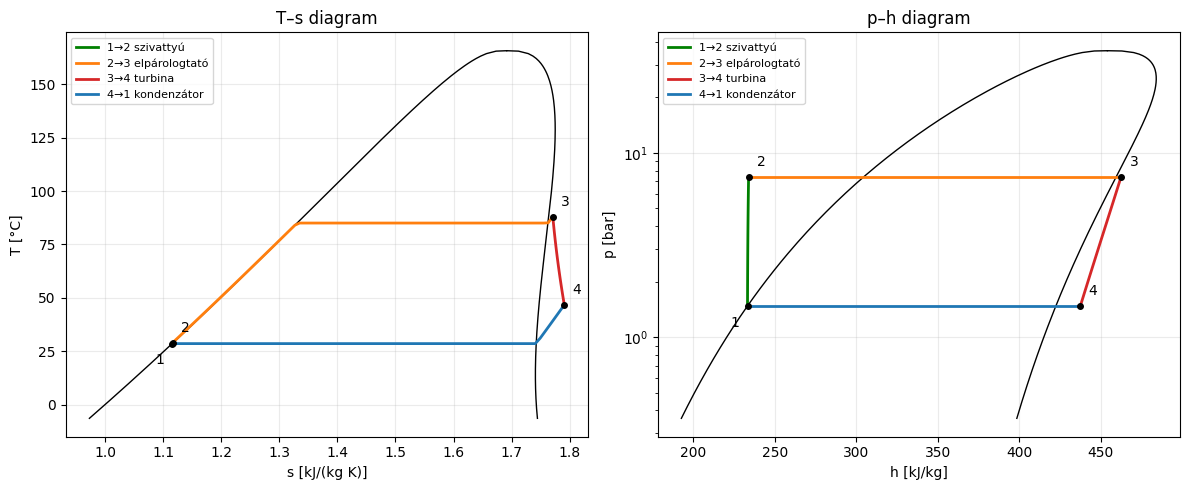

In [ ]:

fluid = REFERENCE_FLUID
st = reference["states"]
e = reference["assumptions"]

pl = st["1"]["p_bar"] * 1e5
ph = st["3"]["p_bar"] * 1e5
h = lambda i: st[i]["h_kJ_kg"] * 1000
s = lambda i: st[i]["s_kJ_kgK"] * 1000

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Telitesi dom a kritikus pontig
Tc = PropsSI("TCRIT", fluid)
dc = PropsSI("RHOCRIT", fluid)
T = np.linspace(max(PropsSI("TMIN", fluid) + 3,
                    perf["T_cond_C"] + 238.15), Tc - 0.2, 150)

for q in (0, 1):
    S = [PropsSI("S", "T", float(t), "Q", q, fluid)/1000 for t in T]
    H = [PropsSI("H", "T", float(t), "Q", q, fluid)/1000 for t in T]
    P = [PropsSI("P", "T", float(t), "Q", q, fluid)/1e5 for t in T]

    S.append(PropsSI("S", "T", Tc, "D", dc, fluid)/1000)
    H.append(PropsSI("H", "T", Tc, "D", dc, fluid)/1000)
    P.append(PropsSI("PCRIT", fluid)/1e5)

    ax1.plot(S, np.r_[T, Tc] - 273.15, "k", lw=1)
    ax2.plot(H, P, "k", lw=1)

# Egy folyamat kirajzolasa mindket diagramon
def draw(P, H, label, color):
    S = [PropsSI("S", "P", float(p), "H", float(v), fluid)/1000
         for p, v in zip(P, H)]
    T = [PropsSI("T", "P", float(p), "H", float(v), fluid)-273.15
         for p, v in zip(P, H)]

    ax1.plot(S, T, color=color, label=label, lw=2)
    ax2.plot(H/1000, P/1e5, color=color, label=label, lw=2)

# 1 -> 2: szivattyu
P = np.linspace(pl, ph, 30)
H = np.array([h("1") + (PropsSI("H", "P", float(p), "S", s("1"), fluid)
              - h("1")) / e["eta_pump"] for p in P])
draw(P, H, "1->2 szivattyu", "green")

# 2 -> 3: elparologtato
draw(np.full(80, ph), np.linspace(h("2"), h("3"), 80),
     "2->3 elparologtato", "tab:orange")

# 3 -> 4: turbina
P = np.geomspace(ph, pl, 50)
H = np.array([h("3") - e["eta_turbine"] *
              (h("3") - PropsSI("H", "P", float(p), "S", s("3"), fluid))
              for p in P])
draw(P, H, "3->4 turbina", "tab:red")

# 4 → 1: kondenzator
draw(np.full(80, pl), np.linspace(h("4"), h("1"), 80),
     "4->1 kondenzator", "tab:blue")

# allapotpontok
for i, v in st.items():
    offset = (-12, -15) if i == "1" else (6, 8)

    ax1.plot(v["s_kJ_kgK"], v["T_C"], "ko", ms=4)
    ax1.annotate(i, (v["s_kJ_kgK"], v["T_C"]),
                 xytext=offset, textcoords="offset points")

    ax2.plot(v["h_kJ_kg"], v["p_bar"], "ko", ms=4)
    ax2.annotate(i, (v["h_kJ_kg"], v["p_bar"]),
                 xytext=offset, textcoords="offset points")

ax1.set(xlabel="s [kJ/(kg K)]", ylabel="T [°C]", title="T–s diagram")
ax2.set(xlabel="h [kJ/kg]", ylabel="p [bar]", title="p–h diagram")
ax2.set_yscale("log")

for ax in (ax1, ax2):
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()


## 5. Érvényességi kör és további feladatok

- Egyszerű, szubkritikus ORC; a hőcserélő és a termálvíz egyfázisú, állandó fajhőjű közelítésen alapul.
- Hőmérsékletek, hozam, pinch és komponenshatásfokok jelenleg **mérési adatokkal nem igazolt előzetes feltevések**.
- A kondenzációs hőmérséklet a külső levegőnél 15 K-nel magasabbnak feltételezett; a valós léghűtő kialakítása és ventilátorvesztesége Hanna rendszermodelljéhez tartozik.
- A motor stabil bemenete a p_elp. Nincs ebben a notebookban p_elp-söprés, éves energiahozam-maximalizálás, 8760 órás futtatás, NPV vagy BYD-fogyasztáselemzés.
- A kiválasztott R1233zd(E) előzetes demonstrációs jelölt, nem végleges éves optimum.
- A T–s és p–h diagramok az állapotpontok ellenőrzésére valók; a pumpa és a turbina köztes pályáját sematikusan ábrázoljuk.

**Források:** [CoolProp dokumentáció](https://coolprop.org/coolprop/HighLevelAPI.html), [CoolProp ábrázolási útmutató](https://coolprop.org/coolprop/python-plotting.html), [US DOE – Geothermal Electricity Generation](https://www.energy.gov/hgeo/geothermal/geothermal-electricity-generation).
